# Chapter 3: Dimensionality Reduction Techniques

Introduction to Dimensionality Reduction

Reduksi dimensi adalah proses mengompresi fitur masukan (dimensi) dalam dataset dengan tetap mempertahankan informasi yang paling relevan. Alasan utama melakukan reduksi dimensi meliputi:
1. Menyederhanakan Data: Mengurangi kompleksitas data sehingga lebih mudah diinterpretasikan.
2. Mengurangi Biaya Komputasi: Jumlah fitur yang lebih sedikit mempercepat waktu latih (training time).
3. Meningkatkan Performa Model: Mengatasi masalah overfitting dan curse of dimensionality dengan menghapus noise atau fitur redundan.
4. Mempermudah Visualisasi: Memproyeksikan data berdimensi tinggi ke 2D atau 3D

Secara garis besar, teknik reduksi dimensi dibagi menjadi dua:
- Feature Selection: Memilih subset fitur asli tanpa mengubah nilainya (misal: RFE, Lasso).
- Feature Extraction: Memunculkan ruang fitur baru berdimensi lebih rendah melalui transformasi matematika (misal: PCA, LDA, t-SNE).

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
import warnings

# Inisialisasi awal & library dasar
np.random.seed(2024)
warnings.simplefilter(action='ignore', category=FutureWarning)

# Memuat dataset Wine (178 sampel, 13 fitur, 3 kelas)
wine = load_wine()
X_wine = wine.data
y_wine = wine.target

print(f"Bentuk Dataset Wine: {X_wine.shape}")
print(f"Jumlah Sampel per Kelas: {np.bincount(y_wine)}")

Bentuk Dataset Wine: (178, 13)
Jumlah Sampel per Kelas: [59 71 48]


- load_wine(): Mengambil dataset standar klasifikasi Wine dari scikit-learn yang memiliki 13 fitur kimiawi kontinu.

- X_wine.shape: Menunjukkan data awal yang terdiri dari 178 baris (sampel) dan 13 kolom (fitur). Fitur-fitur ini memiliki skala yang sangat berbeda (misal: proline hingga ratusan, sementara nonflavanoid_phenols di sekitar 0.3).

# Transforming Datasets with PCA

Principal Component Analysis (PCA) adalah teknik reduksi dimensi unsupervised yang mentransformasikan data ke sistem koordinat baru. Sumbu baru ini, yang disebut Principal Components (PC), ditentukan berdasarkan arah varians terbesar dalam data.
- PCA bersifat Unsupervised: PCA hanya melihat matriks fitur $X$ dan tidak pernah menggunakan label target $y$.
- Wajib Standardization: Karena PCA mencari arah varians terbesar, fitur dengan skala numerik besar akan mendominasi jika data tidak di-skala terlebih dahulu.

Dimensi Awal: 13 fitur -> Dimensi Baru: 2 komponen
Varians PC1: 36.20%
Varians PC2: 19.21%
Total Varians Terjelaskan (Cumulative): 55.41%


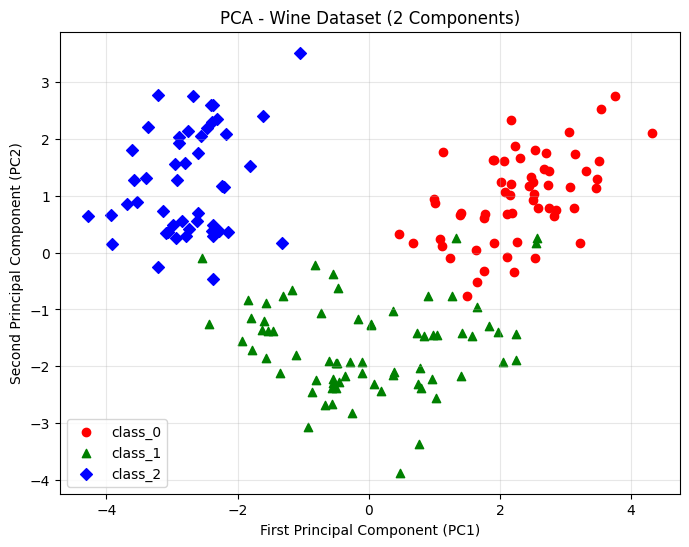

In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# 1. Membuat Pipeline: Standardisasi -> PCA (2 komponen)
pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2))
])

# 2. Fit dan Transformasi
X_pca = pca_pipeline.fit_transform(X_wine)

# 3. Mengekstrak Rasio Varians
pca = pca_pipeline.named_steps['pca']
exp_var = pca.explained_variance_ratio_

print(f"Dimensi Awal: {X_wine.shape[1]} fitur -> Dimensi Baru: {X_pca.shape[1]} komponen")
print(f"Varians PC1: {exp_var[0]:.2%}")
print(f"Varians PC2: {exp_var[1]:.2%}")
print(f"Total Varians Terjelaskan (Cumulative): {sum(exp_var):.2%}")

# Visualisasi PCA
plt.figure(figsize=(8, 6))
for i, color, marker in zip(range(3), ['r', 'g', 'b'], ['o', '^', 'D']):
    plt.scatter(X_pca[y_wine == i, 0], X_pca[y_wine == i, 1],
                c=color, marker=marker, label=wine.target_names[i])
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.title('PCA - Wine Dataset (2 Components)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Scree Plot: Determining Optimal Components

Saat menggunakan PCA, pertanyaan utamanya adalah: Berapa banyak komponen yang harus dipertahankan?

Untuk menjawabnya, kita menggunakan Scree Plot. Grafik ini menampilkan rasio varians terjelaskan dari setiap komponen beserta kumulatifnya. Aturan umum (rule of thumb) yang biasa digunakan adalah memilih jumlah komponen yang mampu mempertahankan 90% hingga 95% total varians.

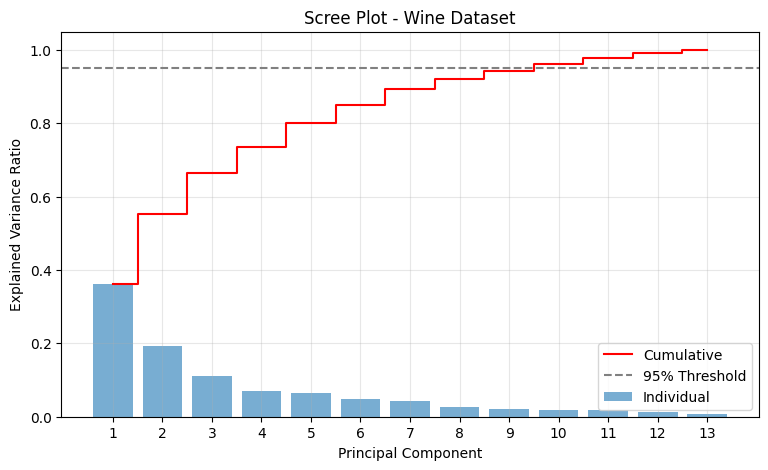

Jumlah komponen untuk mencapai >=95% varians: 10 komponen


In [ ]:
# PCA dengan semua komponen (13 komponen)
pca_full = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA())
])
pca_full.fit(X_wine)

full_pca = pca_full.named_steps['pca']
cum_variance = np.cumsum(full_pca.explained_variance_ratio_)

# Scree Plot
plt.figure(figsize=(9, 5))
x_axis = np.arange(1, len(cum_variance) + 1)
plt.bar(x_axis, full_pca.explained_variance_ratio_, alpha=0.6, label='Individual')
plt.step(x_axis, cum_variance, where='mid', color='red', label='Cumulative')
plt.axhline(y=0.95, color='gray', linestyle='--', label='95% Threshold')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot - Wine Dataset')
plt.xticks(x_axis)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Mencari batas 95% varians
components_95 = np.argmax(cum_variance >= 0.95) + 1
print(f"Jumlah komponen untuk mencapai >=95% varians: {components_95} komponen")

- PCA() tanpa n_components: Mempertahankan seluruh komponen (13 PC) untuk melihat spektrum varians lengkap.

- np.cumsum(): Menghitung akumulasi persentase varians.

- Dari grafik terlihat bahwa untuk melampaui ambang batas 95% varians, kita membutuhkan 10 dari 13 komponen. Tiga komponen terakhir hanya menyumbang sekitar 3.8% varians dan bisa dibuang sebagai noise.

# Maximizing Class Separability with LDA

Linear Discriminant Analysis (LDA) adalah teknik reduksi dimensi supervised. Berbeda dengan PCA yang memaksimalkan varians total tanpa melihat label, LDA bertujuan untuk memaksimalkan pemisahan antarkelas (class separability).

- Formulasi Matematika: LDA memaksimalkan rasio pemisahan antarkelas (between-class scatter, $S_B$) terhadap variansi di dalam kelas (within-class scatter, $S_W$).
- Batasan Komponen: LDA dapat menghasilkan maksimum $\min(p, C - 1)$ komponen, dengan $p$ adalah jumlah fitur dan $C$ adalah jumlah kelas. Untuk Wine dataset ($C=3$), LDA maksimal hanya bisa menghasilkan $\min(13, 3-1) = \mathbf{2\ \text{komponen}}$.

Dimensi setelah LDA: (178, 2)
Rasio Varians Discriminant LD1: 68.75%
Rasio Varians Discriminant LD2: 31.25%


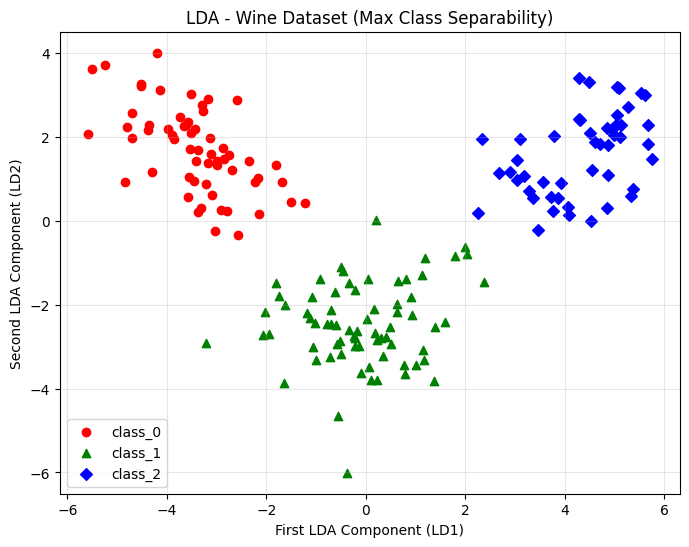

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Pipeline LDA (LDA membutuhkan label y saat dipanggil fit)
lda_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(n_components=2))
])

# Fit dan transform (wajib menyertakan y_wine!)
X_lda = lda_pipeline.fit_transform(X_wine, y_wine)

lda = lda_pipeline.named_steps['lda']
print(f"Dimensi setelah LDA: {X_lda.shape}")
print(f"Rasio Varians Discriminant LD1: {lda.explained_variance_ratio_[0]:.2%}")
print(f"Rasio Varians Discriminant LD2: {lda.explained_variance_ratio_[1]:.2%}")

# Visualisasi LDA
plt.figure(figsize=(8, 6))
for i, color, marker in zip(range(3), ['r', 'g', 'b'], ['o', '^', 'D']):
    plt.scatter(X_lda[y_wine == i, 0], X_lda[y_wine == i, 1],
                c=color, marker=marker, label=wine.target_names[i])
plt.xlabel('First LDA Component (LD1)')
plt.ylabel('Second LDA Component (LD2)')
plt.title('LDA - Wine Dataset (Max Class Separability)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

- lda_pipeline.fit_transform(X_wine, y_wine): Berbeda dari PCA, fungsi fit_transform pada LDA wajib menerima argumen y_wine agar dapat menghitung matriks pemisahan kelas $S_B$ dan $S_W$.

- Hasil Visualisasi: LD1 dan LD2 memisahkan ketiga kelompok kelas wine secara jauh lebih bersih dan terpisah sempurna tanpa ada overlap berlebih jika dibandingkan dengan hasil PCA.

# t-SNE and Data Visualization

t-Distributed Stochastic Neighbor Embedding (t-SNE) adalah teknik reduksi dimensi non-linier yang dirancang khusus untuk visualisasi data.
- Cara Kerja: t-SNE mengukur kemiripan antar-titik data di ruang berdimensi tinggi (menggunakan distribusi Gaussian) dan mencoba mencocokkan kemiripan tersebut di ruang 2D/3D (menggunakan distribusi Student-t) dengan meminimalkan Kullback-Leibler (KL) divergence
- Keunggulan: Mampu menangkap struktur non-linier dan kelompok kompleks yang gagal dipisahkan oleh metode linier seperti PCA/LDA.
- Aturan Penting: t-SNE hanya untuk visualisasi! Komponen t-SNE tidak bisa mengeksekusi metode transform() pada data baru (tidak ada matriks proyeksi yang disimpan) dan jarak antar-kluster pada plot t-SNE tidak mencerminkan jarak riil.

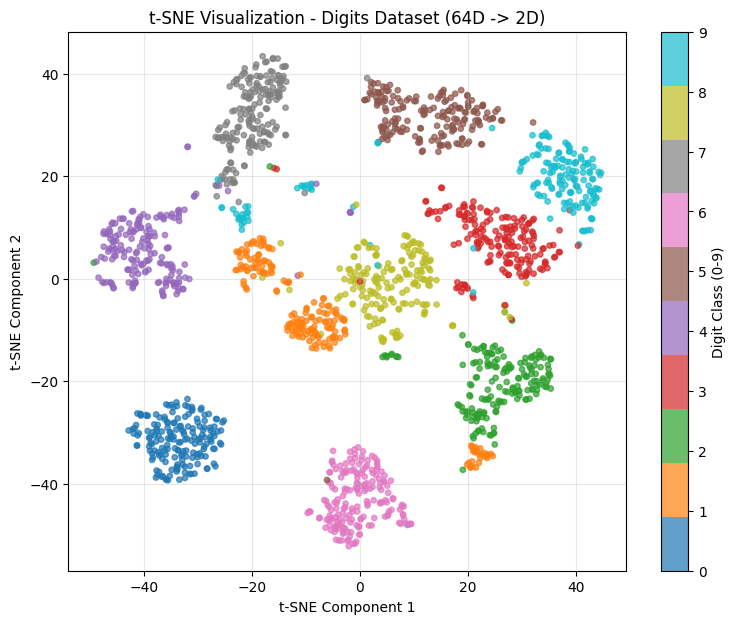

In [ ]:
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE

# Memuat dataset MNIST Digits (1797 sampel, 64 fitur pixel, 10 kelas)
digits = load_digits()
X_digits, y_digits = digits.data, digits.target

# Pipeline t-SNE
tsne_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('tsne', TSNE(n_components=2, random_state=2024))
])

# Transformasi data digit ke 2D
X_tsne = tsne_pipeline.fit_transform(X_digits)

# Visualisasi t-SNE
plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_digits, cmap='tab10', alpha=0.7, s=15)
plt.colorbar(scatter, label='Digit Class (0-9)')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('t-SNE Visualization - Digits Dataset (64D -> 2D)')
plt.grid(True, alpha=0.3)
plt.show()

- load_digits(): Dataset berupa gambar digit angka berukuran $8 \times 8$ piksel (total 64 fitur).

- TSNE(n_components=2): Berhasil memproyeksikan data dari 64 dimensi menjadi 2 dimensi.

- Hasil Plot: Terbentuk 10 kelompok (clusters) terpisah yang bersih mewakili setiap digit dari 0 hingga 9. Metode linier seperti PCA akan kesulitan memisahkan 10 kelompok ini dalam 2D.

# Impact on Model Performance

Penggunaan teknik reduksi dimensi sebagai tahap pra-pemrosesan (preprocessing) memiliki dampak langsung terhadap performa model klasifikasi downstream.
- Membuang komponen ber-varians rendah (noise) berfungsi sebagai bentuk regulerisasi yang mencegah overfitting.
- LDA umumnya memberikan peningkatan performa klasifikasi yang paling drastis dengan dimensi paling sedikit karena telah dioptimalkan secara supervised

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

# 1. Baseline: Menggunakan seluruh 13 fitur tanpa reduksi dimensi
pipe_base = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=5000, random_state=2024))
])
score_base = cross_val_score(pipe_base, X_wine, y_wine, cv=5, scoring='accuracy').mean()

# 2. PCA dengan 2 komponen
pipe_pca2 = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2)),
    ('clf', LogisticRegression(max_iter=5000, random_state=2024))
])
score_pca2 = cross_val_score(pipe_pca2, X_wine, y_wine, cv=5, scoring='accuracy').mean()

# 3. PCA dengan 10 komponen (95% varians)
pipe_pca10 = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=10)),
    ('clf', LogisticRegression(max_iter=5000, random_state=2024))
])
score_pca10 = cross_val_score(pipe_pca10, X_wine, y_wine, cv=5, scoring='accuracy').mean()

# 4. LDA dengan 2 komponen
pipe_lda2 = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(n_components=2)),
    ('clf', LogisticRegression(max_iter=5000, random_state=2024))
])
score_lda2 = cross_val_score(pipe_lda2, X_wine, y_wine, cv=5, scoring='accuracy').mean()

print(f"Akurasi Baseline (13 Fitur) : {score_base:.4f}")
print(f"Akurasi PCA (2 Komponen)   : {score_pca2:.4f}")
print(f"Akurasi PCA (10 Komponen)  : {score_pca10:.4f}")
print(f"Akurasi LDA (2 Komponen)   : {score_lda2:.4f}")

Akurasi Baseline (13 Fitur) : 0.9832
Akurasi PCA (2 Komponen)   : 0.9551
Akurasi PCA (10 Komponen)  : 0.9833
Akurasi LDA (2 Komponen)   : 0.9832
